[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/16_scene_finder.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🔎 Scene Finder: Is There Data for My Project?
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Every good project idea runs into the same question sooner or later: **is there suitable imagery over my area, at the right time?** Hyperspectral satellites such as Tanager are *tasked*: they image targets on request instead of mapping the whole globe every few days as Sentinel-2 does. The open archive is therefore **sparse**. Checking data availability is the first thing to do when scoping a project, not the last.

In this practical you search the whole Tanager open-data archive by area, date and quality, find places imaged more than once (needed for change detection), and write the **data availability** section of your project scoping document.

**What you will learn**
- How Planet's **static STAC catalogue** is organised, and how to build a searchable index of it
- How to **search** scenes by bounding box, point, date, cloud cover and viewing angle
- How to judge scene quality from metadata **and** thumbnails (and why a cloud percentage can mislead)
- How to find **repeat coverage** and **overlapping scene pairs** for change detection
- Where to find **complementary data** (EnMAP, PRISMA, EMIT, Sentinel-2)
- How to turn a search into the *data availability* section of `templates/project_scoping_template.md`

**Prerequisites:** `00_EO_data_quickstart_notebook.ipynb` (what STAC is).

**Data:** `data/tanager_catalog_index.geojson`, an index of all Tanager core-imagery items built with `hu.build_catalog_index()`. The notebook works **offline** on that cached index. Thumbnails, the optional basemap, the Sentinel-2 search and refreshing the index need **internet**.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas", "pystac-client", "planetary-computer", "leafmap", "localtileserver"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py and data/tanager_catalog_index.geojson, then uncomment:
# %pip install -q h5py numpy matplotlib pandas geopandas shapely requests pystac-client planetary-computer
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_colwidth", 60)
REFRESH_INDEX = False     # True = crawl Planet's STAC catalogue again (needs internet, 1–3 minutes)

## 1. The Tanager open-data catalogue

Planet publishes Tanager open data as a **static STAC catalogue**: a tree of JSON files (catalogue → collections → items), with no search API. To search it you first walk the tree and collect the metadata of every item. `hu.build_catalog_index()` does exactly that and saves the result as a GeoJSON file, one footprint polygon per item. `hu.load_catalog_index()` loads it (and builds it if it's missing).

```
catalog.json
├── agriculture/collection.json ──► 20250608_091605_90_4001/…json (item: footprint, properties, assets)
├── coastal-water-bodies/…
├── fire/…   urban/…   natural-lands/…   GHG-plumes/…   energy-mining/…   snow-ice/…   ROCX2025/…
```

In [2]:
index = hu.load_catalog_index(refresh=REFRESH_INDEX)
print(f"{len(index)} catalogue entries, {index['id'].nunique()} unique scenes")
print("Columns:", list(index.columns))
index[["id", "collection", "datetime", "location", "cloud_percent", "off_nadir"]].head()

276 catalogue entries, 153 unique scenes
Columns: ['id', 'collection', 'datetime', 'location', 'cloud_percent', 'light_haze_percent', 'off_nadir', 'sun_elevation', 'gsd', 'item_url', 'sr_url', 'thumbnail', 'visual', 'geometry']


,id,collection,datetime,location,cloud_percent,off_nadir
0,20240925_185504_87_4001,natural-lands,2024-09-25 18:55:04.870000+00:00,"Nye County, Nevada, United States",2,11.9
1,20240925_185504_87_4001,energy-mining,2024-09-25 18:55:04.870000+00:00,"Nye County, Nevada, United States",2,11.9
2,20240925_185509_74_4001,natural-lands,2024-09-25 18:55:09.741000+00:00,"Esmeralda County, Nevada, United States",1,12.0
3,20240925_185509_74_4001,energy-mining,2024-09-25 18:55:09.741000+00:00,"Esmeralda County, Nevada, United States",1,12.0
4,20241004_081921_28_4001,GHG-plumes,2024-10-04 08:19:21.284000+00:00,"As-Sa'duni, Khasham Subdistrict, Deir ez-Zor District, D...",0,2.8


### 1.1 One row per scene

A scene can belong to **several collections**: the Malibu fire scene is in both `fire` and `natural-lands`. Counting rows would count those scenes twice, so we deduplicate and keep the list of collections per scene.

In [3]:
cols_per_scene = index.groupby("id")["collection"].apply(lambda s: ", ".join(sorted(set(s))))
scenes = (index.drop_duplicates("id").drop(columns="collection")
          .merge(cols_per_scene.rename("collections"), left_on="id", right_index=True)
          .sort_values("datetime").reset_index(drop=True))
scenes["country"] = scenes["location"].str.split(",").str[-1].str.strip()
scenes["month"] = scenes["datetime"].dt.strftime("%Y-%m")
centroids = scenes.to_crs(6933).centroid.to_crs(4326)          # centroid in an equal-area CRS
scenes["lon"], scenes["lat"] = centroids.x, centroids.y
scenes["area_km2"] = scenes.to_crs(6933).area / 1e6
print(f"{len(scenes)} unique scenes from {scenes['datetime'].min():%d %b %Y} to {scenes['datetime'].max():%d %b %Y}")
print(f"Scene footprints: {scenes['area_km2'].min():.0f}–{scenes['area_km2'].max():.0f} km² (median {scenes['area_km2'].median():.0f} km²)")
print(f"Scenes in more than one collection: {(scenes['collections'].str.contains(',')).sum()}")
scenes[["id", "collections", "datetime", "country", "cloud_percent", "off_nadir"]].tail()

153 unique scenes from 25 Sep 2024 to 29 Oct 2025
Scene footprints: 322–879 km² (median 394 km²)
Scenes in more than one collection: 123


,id,collections,datetime,country,cloud_percent,off_nadir
148,20251001_165054_91_4001,"ROCX2025, urban",2025-10-01 16:50:54.913000+00:00,United States,0,17.3
149,20251015_165255_92_4001,"ROCX2025, coastal-water-bodies",2025-10-15 16:52:55.924000+00:00,United States,0,17.9
150,20251015_165301_89_4001,"ROCX2025, urban",2025-10-15 16:53:01.898000+00:00,United States,5,18.7
151,20251029_165455_83_4001,"ROCX2025, coastal-water-bodies",2025-10-29 16:54:55.837000+00:00,United States,0,16.1
152,20251029_165501_94_4001,"ROCX2025, urban",2025-10-29 16:55:01.944000+00:00,United States,0,16.1


## 2. What's in the archive?

Before searching for your own area, get a feel for the archive: which themes, which months, what quality.

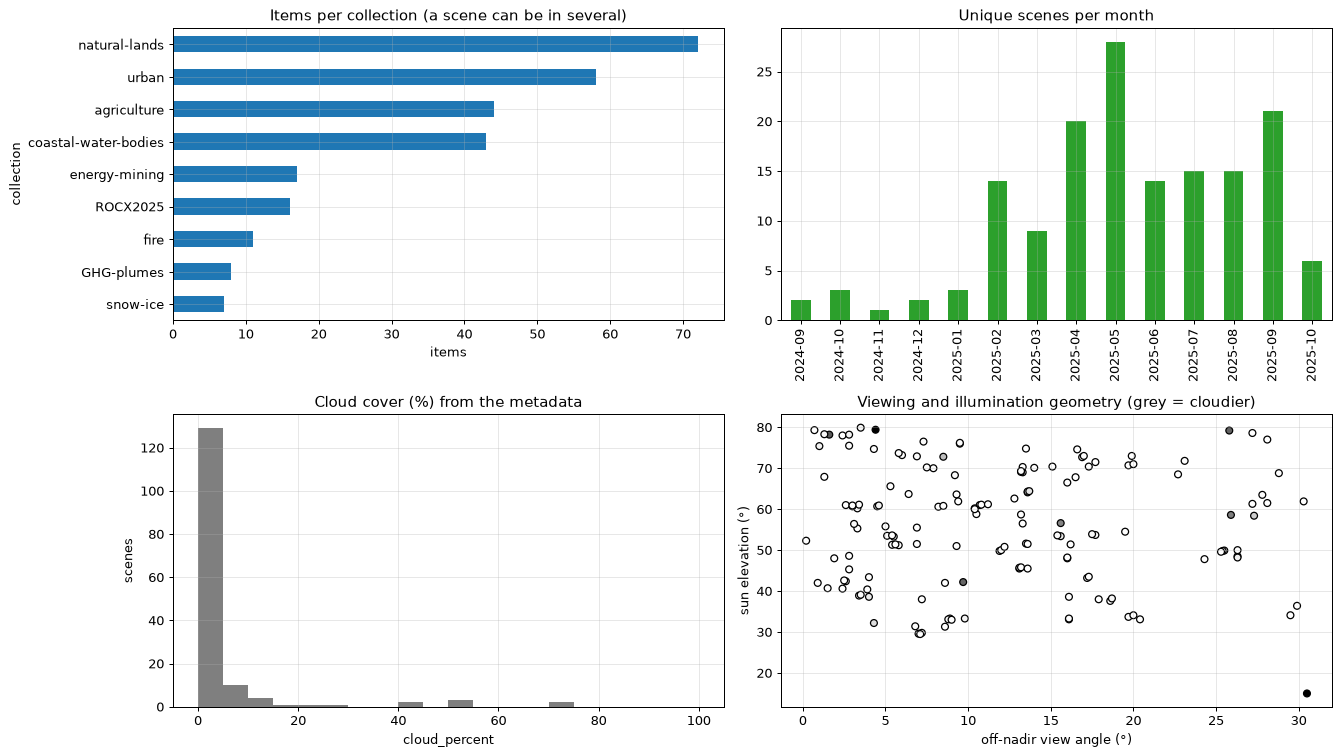

Top 10 countries:
country
United States    52
Argentina        15
Netherlands       9
Canada            7
India             4
Mexico            4
El Salvador       3
Russia            3
Vietnam           3
Australia         3


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
index["collection"].value_counts().sort_values().plot.barh(ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title("Items per collection (a scene can be in several)"); axes[0, 0].set_xlabel("items")
scenes.groupby("month").size().plot.bar(ax=axes[0, 1], color="tab:green")
axes[0, 1].set_title("Unique scenes per month"); axes[0, 1].set_xlabel("")
axes[1, 0].hist(scenes["cloud_percent"], bins=np.arange(0, 105, 5), color="tab:gray")
axes[1, 0].set_title("Cloud cover (%) from the metadata"); axes[1, 0].set_xlabel("cloud_percent"); axes[1, 0].set_ylabel("scenes")
axes[1, 1].scatter(scenes["off_nadir"], scenes["sun_elevation"], c=scenes["cloud_percent"], cmap="Greys", edgecolor="k", s=30)
axes[1, 1].set_xlabel("off-nadir view angle (°)"); axes[1, 1].set_ylabel("sun elevation (°)")
axes[1, 1].set_title("Viewing and illumination geometry (grey = cloudier)")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Top 10 countries:"); print(scenes["country"].value_counts().head(10).to_string())

Things to notice:
- Most scenes are nearly **cloud-free**. That's a selection effect: open-data scenes were picked as good examples. Several of the "cloudy" ones are in fact bright deserts (section 4.2).
- **Off-nadir angles** go up to ~30°. Large angles mean larger pixels (the metadata `gsd` grows), longer atmospheric paths and different sun–target–sensor geometry (BRDF effects). Keep that in mind when comparing two dates.
- **Sun elevation** varies with latitude and season. Low sun means dark scenes, long shadows and lower SNR.

## 3. A world view

We draw the scene centroids on a world map. The country outlines come from *Natural Earth*, downloaded on the fly; offline, the plot falls back to a plain longitude/latitude grid.

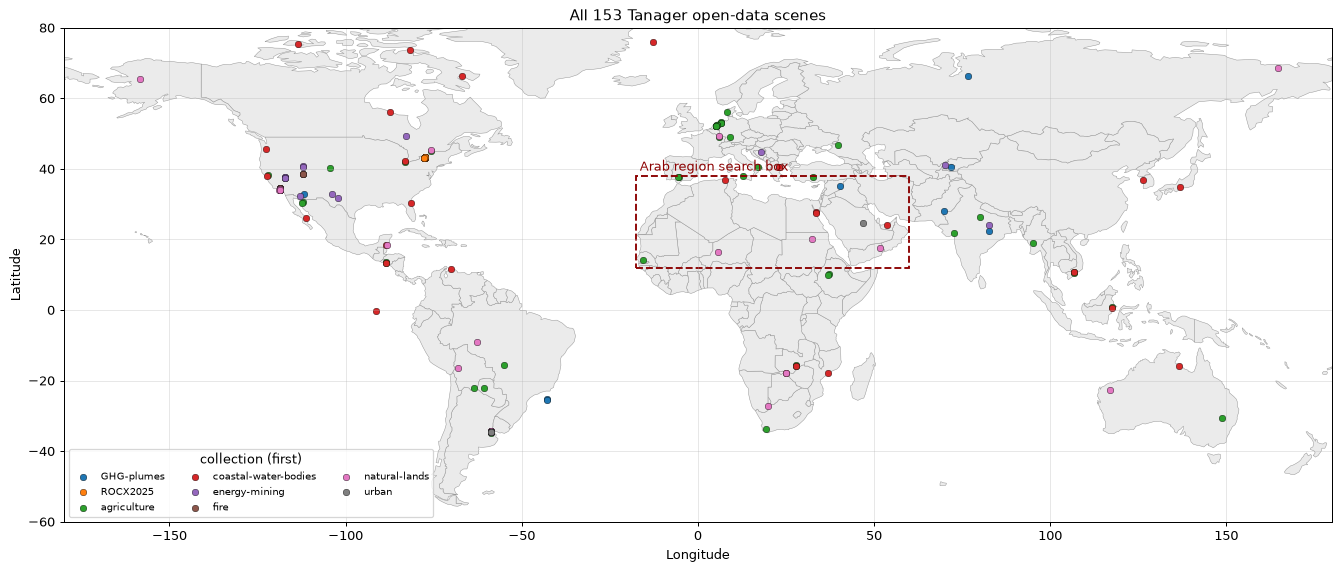

In [5]:
def load_world():
    try:
        return gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip")
    except Exception as err:  # offline or blocked: carry on without a basemap
        print("No basemap (offline?):", type(err).__name__)
        return None

world = load_world()
ARAB_BBOX = (-17.5, 12.0, 60.0, 38.0)     # (west, south, east, north), roughly Mauritania to Oman

fig, ax = plt.subplots(figsize=(15, 7.2))
if world is not None:
    world.plot(ax=ax, color="0.92", edgecolor="0.6", lw=0.4)
for col, grp in scenes.assign(first=scenes["collections"].str.split(",").str[0]).groupby("first"):
    ax.scatter(grp["lon"], grp["lat"], s=28, label=col, edgecolor="k", lw=0.3)
w, s, e, n = ARAB_BBOX
ax.add_patch(plt.Rectangle((w, s), e - w, n - s, fill=False, ec="darkred", lw=1.5, ls="--"))
ax.text(w + 1, n + 1.5, "Arab region search box", color="darkred")
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(title="collection (first)", fontsize=8, ncol=3, loc="lower left"); ax.grid(alpha=0.3)
ax.set_title(f"All {len(scenes)} Tanager open-data scenes")
plt.tight_layout(); plt.show()

## 4. Searching the archive

A search is a sequence of filters on the scene table. The spatial filter tests whether a scene **footprint** intersects your area of interest (AOI), which is more accurate than testing the centroid. An AOI can be a bounding box or a point with a buffer.

In [6]:
from shapely.geometry import box, Point

def search_scenes(scenes, bbox=None, point=None, buffer_km=0.0, start=None, end=None,
                  max_cloud=None, max_off_nadir=None, collections=None, countries=None):
    """Filter the scene table. bbox=(west, south, east, north) in degrees; point=(lon, lat)."""
    out = scenes
    if bbox is not None:
        out = out[out.intersects(box(*bbox))]
    if point is not None:
        aoi = gpd.GeoSeries([Point(point)], crs=4326).to_crs(6933).buffer(buffer_km * 1000 + 1).to_crs(4326).iloc[0]
        out = out[out.intersects(aoi)]
    if start is not None:
        out = out[out["datetime"] >= pd.Timestamp(start, tz="UTC")]
    if end is not None:
        out = out[out["datetime"] <= pd.Timestamp(end, tz="UTC")]
    if max_cloud is not None:
        out = out[out["cloud_percent"] <= max_cloud]
    if max_off_nadir is not None:
        out = out[out["off_nadir"] <= max_off_nadir]
    if collections is not None:
        out = out[out["collections"].apply(lambda c: any(k in c.split(", ") for k in collections))]
    if countries is not None:
        out = out[out["country"].isin(countries)]
    return out.copy()

SHOW = ["id", "collections", "datetime", "location", "cloud_percent", "off_nadir"]

### 4.1 The Arab region

A bounding box from Mauritania to Oman also catches Spain, Türkiye and the Sahel, so we add a country filter.

In [7]:
ARAB_COUNTRIES = ["Algeria", "Bahrain", "Comoros", "Djibouti", "Egypt", "Iraq", "Jordan", "Kuwait", "Lebanon",
                  "Libya", "Mauritania", "Morocco", "Oman", "Palestinian Territory", "Palestine", "Qatar",
                  "Saudi Arabia", "Somalia", "Sudan", "Syria", "Tunisia", "United Arab Emirates", "Yemen"]

in_box = search_scenes(scenes, bbox=ARAB_BBOX)
arab = search_scenes(in_box, countries=ARAB_COUNTRIES)
print(f"{len(in_box)} scenes intersect the box, {len(arab)} of them in Arab League countries")
arab[SHOW]

14 scenes intersect the box, 8 of them in Arab League countries


,id,collections,datetime,location,cloud_percent,off_nadir
2,20241004_081921_28_4001,GHG-plumes,2024-10-04 08:19:21.284000+00:00,"As-Sa'duni, Khasham Subdistrict, Deir ez-Zor District, D...",0,2.8
65,20250509_090323_87_4001,natural-lands,2025-05-09 09:03:23.870000+00:00,"Northern State, Sudan",0,0.7
69,20250511_074311_00_4001,coastal-water-bodies,2025-05-11 07:43:11+00:00,"Tarif, Al Dhafrah Region, Abu Dhabi Emirate, United Arab...",51,25.8
73,20250515_080954_16_4001,urban,2025-05-15 08:09:54.165000+00:00,"As Sali Municipality, Riyadh governorate, Riyadh Region,...",74,4.4
82,20250601_104901_58_4001,"coastal-water-bodies, natural-lands",2025-06-01 10:49:01.582000+00:00,Algeria,0,19.9
85,20250606_090504_75_4001,"coastal-water-bodies, natural-lands",2025-06-06 09:05:04.757000+00:00,"Red Sea, Egypt",7,3.5
90,20250608_074757_58_4001,natural-lands,2025-06-08 07:47:57.582000+00:00,"Hat District, Al Mahrah Governorate, Yemen",53,1.6
143,20250926_092059_95_4001,"coastal-water-bodies, natural-lands",2025-09-26 09:20:59.952000+00:00,"El Gouna, Red Sea, 84513, Egypt",8,4.6


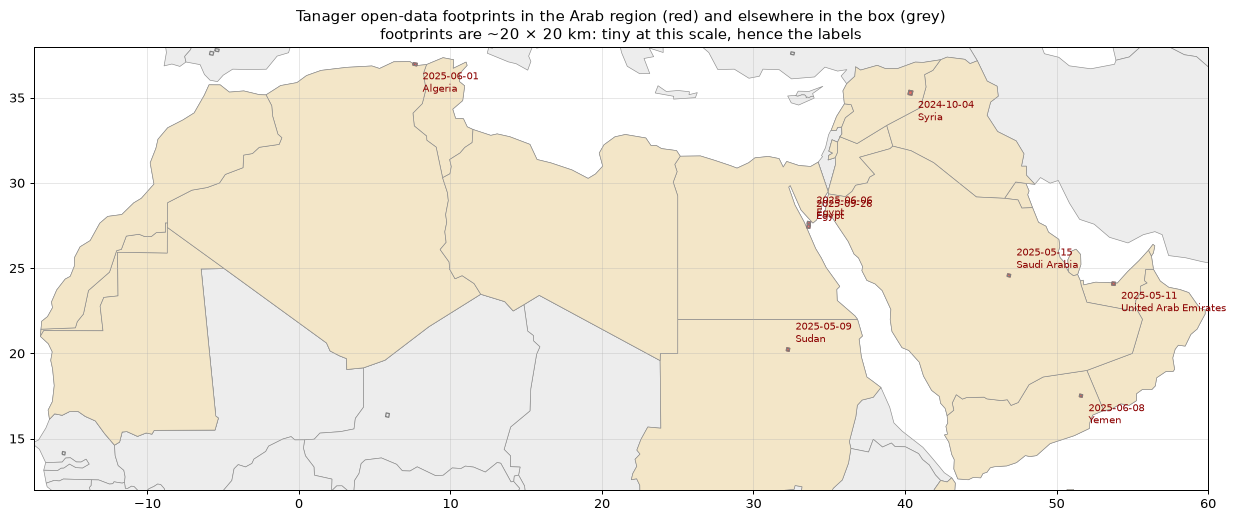

In [8]:
fig, ax = plt.subplots(figsize=(14, 6.3))
if world is not None:
    world.plot(ax=ax, color="0.93", edgecolor="0.55", lw=0.5)
    world[world["NAME"].isin(ARAB_COUNTRIES + ["Palestine", "W. Sahara"])].plot(ax=ax, color="#f3e6c8", edgecolor="0.55", lw=0.5)
in_box.boundary.plot(ax=ax, color="0.5", lw=1)
arab.plot(ax=ax, color="tab:red", alpha=0.6, edgecolor="darkred")
for k, (_, r) in enumerate(arab.iterrows()):
    ax.annotate(f"{r['datetime']:%Y-%m-%d}\n{r['country']}", (r["lon"], r["lat"]), xytext=(6, 6 if k % 2 else -22),
                textcoords="offset points", fontsize=8, color="darkred")
w, s, e, n = ARAB_BBOX
ax.set_xlim(w, e); ax.set_ylim(s, n); ax.grid(alpha=0.3)
ax.set_title("Tanager open-data footprints in the Arab region (red) and elsewhere in the box (grey)\n"
             "footprints are ~20 × 20 km: tiny at this scale, hence the labels")
plt.tight_layout(); plt.show()

### 4.2 Look before you trust: thumbnails

Metadata can mislead, especially over deserts. Below are the thumbnails of the Arab-region scenes (they need internet to display). Compare the **cloud_percent** values with what you see:

- **Riyadh, Saudi Arabia**: 74 % "cloud"
- **Al Mahrah, Yemen**: 53 % "cloud"
- **Al Dhafra, UAE**: 51 % "cloud"

All three thumbnails are **clear**. The provisional (*beta*) cloud mask confuses bright desert sand, gravel plains and **sabkha** (salt flats) with clouds (notebook 11 shows it pixel by pixel). A search with `max_cloud=20` would have thrown away 3 of the 8 Arab-region scenes, including the *only* scenes in Saudi Arabia, Yemen and the UAE. In arid regions, use the cloud percentage as a hint, never as a hard filter.

In [9]:
def thumbnail_gallery(df, width=190):
    cells = []
    for _, r in df.iterrows():
        cells.append(f"""<div style="display:inline-block;margin:4px;text-align:center;font-size:11px;width:{width}px">
            <img src="{r['thumbnail']}" width="{width}" style="border:1px solid #888"/><br>
            <b>{r['datetime']:%Y-%m-%d}</b> · {r['country']}<br>cloud {r['cloud_percent']:.0f}% · off-nadir {r['off_nadir']:.0f}°</div>""")
    display(HTML("".join(cells)))

thumbnail_gallery(arab)
print("Strict cloud filter (≤ 20 %) would keep:", list(search_scenes(arab, max_cloud=20)["country"]))

Strict cloud filter (≤ 20 %) would keep: ['Syria', 'Sudan', 'Algeria', 'Egypt', 'Egypt']


### 4.3 Searching around a point, with dates

For a point AOI we buffer it by a few kilometres, so the whole study area (not just the centre point) has to fall inside the footprint. Here: the Santa Monica Mountains near Malibu, affected by the **Franklin fire (Dec 2024)** and the **Palisades fire (Jan 2025)**.

In [10]:
malibu = search_scenes(scenes, point=(-118.70, 34.05), buffer_km=3)
print(f"{len(malibu)} scenes cover Malibu (± 3 km):")
malibu[SHOW]

6 scenes cover Malibu (± 3 km):


,id,collections,datetime,location,cloud_percent,off_nadir
4,20241025_185056_92_4001,"natural-lands, urban",2024-10-25 18:50:56.926000+00:00,"Malibu, Los Angeles County, California, United States",50,9.7
7,20241215_185916_33_4001,"fire, natural-lands",2024-12-15 18:59:16.350000+00:00,"Malibu, Los Angeles County, California, United States",0,6.8
10,20250123_185518_92_4001,"fire, natural-lands",2025-01-23 18:55:18.926000+00:00,"Unincorporated Santa Monica Mountains, Los Angeles Count...",0,20.0
40,20250407_192247_40_4001,"natural-lands, urban",2025-04-07 19:22:47.400000+00:00,"Unincorporated Santa Monica Mountains, Los Angeles Count...",0,30.3
108,20250726_192422_87_4001,"fire, natural-lands",2025-07-26 19:24:22.887000+00:00,"Unincorporated Santa Monica Mountains, Los Angeles Count...",1,17.0
142,20250920_193207_61_4001,"fire, natural-lands",2025-09-20 19:32:07.628000+00:00,"Malibu, Los Angeles County, California, United States",42,15.6


In [11]:
winter = search_scenes(scenes, point=(-118.70, 34.05), buffer_km=3, start="2024-12-01", end="2025-02-28", max_off_nadir=20)
print("Dec 2024 – Feb 2025, off-nadir ≤ 20°:")
winter[SHOW]

Dec 2024 – Feb 2025, off-nadir ≤ 20°:


,id,collections,datetime,location,cloud_percent,off_nadir
7,20241215_185916_33_4001,"fire, natural-lands",2024-12-15 18:59:16.350000+00:00,"Malibu, Los Angeles County, California, United States",0,6.8
10,20250123_185518_92_4001,"fire, natural-lands",2025-01-23 18:55:18.926000+00:00,"Unincorporated Santa Monica Mountains, Los Angeles Count...",0,20.0


## 5. Repeat coverage and overlapping pairs

**Change detection** (burn scars, crop phenology, urban growth, water quality events) needs at least two images of the *same place*. We look for pairs of scenes whose footprints overlap substantially and report:

- **overlap**: intersection area as a fraction of the *smaller* footprint (1.0 = one scene lies completely inside the other),
- **days**: time between the two acquisitions,
- the difference in **off-nadir angle**, because very different viewing geometry makes comparisons harder.

Areas are computed in an equal-area projection (EPSG:6933), not in degrees.

In [12]:
def find_overlapping_pairs(scenes, min_overlap=0.3, max_days=None):
    ea = scenes.to_crs(6933)[["id", "datetime", "off_nadir", "location", "geometry"]]
    pairs = gpd.sjoin(ea, ea, predicate="intersects", lsuffix="a", rsuffix="b")
    pairs = pairs[pairs["id_a"] < pairs["id_b"]].copy()
    geom = ea.set_index("id").geometry
    pairs["overlap"] = [geom[a].intersection(geom[b]).area / min(geom[a].area, geom[b].area)
                        for a, b in zip(pairs["id_a"], pairs["id_b"])]
    pairs["days"] = (pairs["datetime_b"] - pairs["datetime_a"]).dt.days.abs()
    pairs["d_off_nadir"] = (pairs["off_nadir_b"] - pairs["off_nadir_a"]).abs()
    pairs = pairs[pairs["overlap"] >= min_overlap]
    if max_days is not None:
        pairs = pairs[pairs["days"] <= max_days]
    return (pairs.rename(columns={"location_a": "location"})
            [["id_a", "id_b", "overlap", "days", "d_off_nadir", "location"]]
            .sort_values(["overlap", "days"], ascending=[False, True]).reset_index(drop=True))

pairs = find_overlapping_pairs(scenes, min_overlap=0.3)
print(f"{len(pairs)} scene pairs overlap by ≥ 30 %")
sites = pairs["location"].str.split(",").str[-1].str.strip().value_counts()
print("Pairs per country:", sites.to_dict())
pairs.head(12).round(2)

121 scene pairs overlap by ≥ 30 %
Pairs per country: {'United States': 89, 'Argentina': 29, 'Netherlands': 3}


,id_a,id_b,overlap,days,d_off_nadir,location
0,20250213_142717_00_4001,20250626_144415_59_4001,1.00,133,3.3,"Primera Sección, Partido de Tigre, Buenos Aires, Argentina"
1,20240925_185504_87_4001,20250222_190237_16_4001,1.00,150,9.5,"Nye County, Nevada, United States"
2,20250704_165212_93_4001,20251029_165501_94_4001,1.00,117,2.9,"Town of Rush, Monroe County, New York, 14543, United States"
3,20250704_165212_93_4001,20251015_165301_89_4001,1.00,103,5.5,"Town of Rush, Monroe County, New York, 14543, United States"
4,20250313_143031_92_4001,20250724_144830_83_4001,1.00,133,1.9,"Don Torcuato, Partido de Tigre, Buenos Aires, Argentina"
5,20250801_165553_11_4001,20251029_165501_94_4001,1.00,88,2.4,"Town of Rush, Monroe County, New York, 14543, United States"
6,20250626_144423_91_4001,20250724_144835_07_4001,0.99,28,1.9,"Castelar, Partido de Morón, Buenos Aires, Argentina"
7,20250213_142717_00_4001,20250313_143015_00_4001,0.99,28,3.0,"Primera Sección, Partido de Tigre, Buenos Aires, Argentina"
8,20250903_164719_92_4001,20250919_170238_88_4001,0.99,16,1.5,"Town of Webster, Monroe County, New York, 14580, United ..."
9,20250903_164714_08_4001,20250919_170233_04_4001,0.99,16,1.7,"Town of Webster, Monroe County, New York, 14580, United ..."


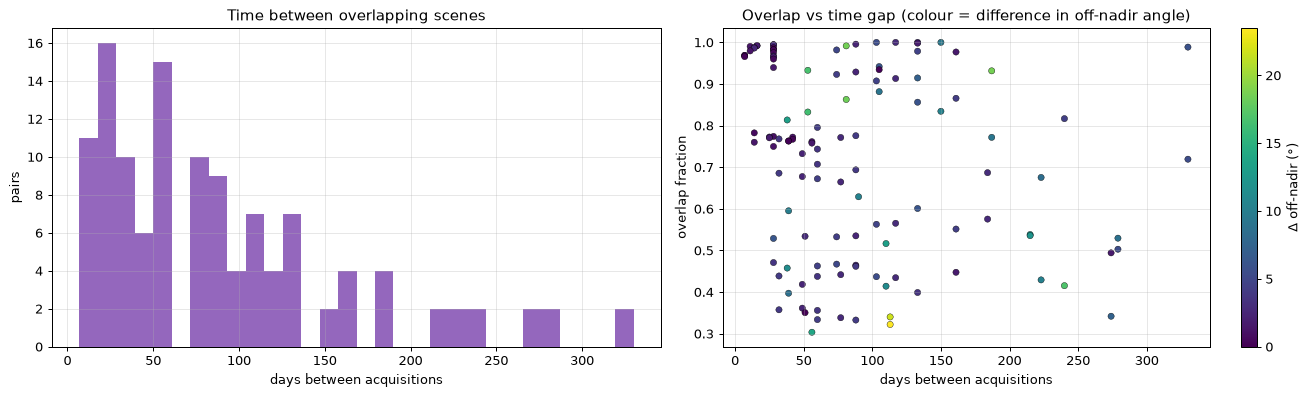

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(pairs["days"], bins=30, color="tab:purple")
axes[0].set_xlabel("days between acquisitions"); axes[0].set_ylabel("pairs"); axes[0].set_title("Time between overlapping scenes")
axes[1].scatter(pairs["days"], pairs["overlap"], c=pairs["d_off_nadir"], cmap="viridis", s=25, edgecolor="k", lw=0.3)
axes[1].set_xlabel("days between acquisitions"); axes[1].set_ylabel("overlap fraction")
axes[1].set_title("Overlap vs time gap (colour = difference in off-nadir angle)")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(pairs["d_off_nadir"].min(), pairs["d_off_nadir"].max()))
plt.colorbar(sm, ax=axes[1], label="Δ off-nadir (°)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Repeat coverage exists, but it is concentrated at a handful of **supersites**: calibration and demonstration sites that Planet imaged repeatedly (Rochester NY for the `ROCX2025` campaign, Buenos Aires, the Netherlands, Nevada, Malibu). For most places in the world, including **every site in the Arab region** at the time this index was built, the open archive has *one* scene. For a change-detection project you'd then either:
- pick one of the supersites,
- combine one Tanager scene (detailed spectral "snapshot") with a **Sentinel-2 / Landsat time series** (dense in time, coarser spectrally), or
- request new acquisitions (the 813 mission, EnMAP and PRISMA accept tasking or proposal requests).

Let's look at the Malibu pair that notebook 30 uses for burn-scar change detection.

Overlapping pairs among the Malibu scenes:


,id_a,id_b,overlap,days,d_off_nadir,location
12,20241025_185056_92_4001,20250920_193207_61_4001,0.99,330,5.9,"Malibu, Los Angeles County, California, United States"
45,20250123_185518_92_4001,20250920_193207_61_4001,0.82,240,4.4,"Unincorporated Santa Monica Mountains, Los Angeles Count..."
46,20241215_185916_33_4001,20250123_185518_92_4001,0.81,38,13.2,"Malibu, Los Angeles County, California, United States"
69,20250123_185518_92_4001,20250726_192422_87_4001,0.69,184,3.0,"Unincorporated Santa Monica Mountains, Los Angeles Count..."
75,20241025_185056_92_4001,20250123_185518_92_4001,0.63,90,10.3,"Malibu, Los Angeles County, California, United States"
85,20241025_185056_92_4001,20241215_185916_33_4001,0.53,51,2.9,"Malibu, Los Angeles County, California, United States"
87,20241215_185916_33_4001,20250920_193207_61_4001,0.53,279,8.8,"Malibu, Los Angeles County, California, United States"
89,20250407_192247_40_4001,20250726_192422_87_4001,0.52,110,13.3,"Unincorporated Santa Monica Mountains, Los Angeles Count..."
104,20241215_185916_33_4001,20250726_192422_87_4001,0.43,223,10.2,"Malibu, Los Angeles County, California, United States"
114,20241025_185056_92_4001,20250726_192422_87_4001,0.34,274,7.3,"Malibu, Los Angeles County, California, United States"


Common area: 296 km²


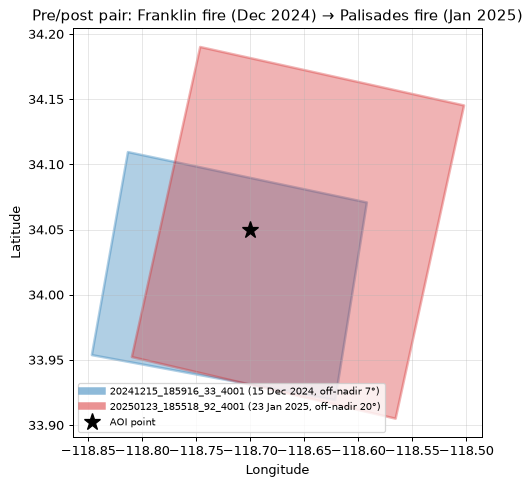

In [14]:
fire_pairs = pairs[pairs["id_a"].isin(malibu["id"]) & pairs["id_b"].isin(malibu["id"])]
print("Overlapping pairs among the Malibu scenes:")
display(fire_pairs.round(2))

a, b = "20241215_185916_33_4001", "20250123_185518_92_4001"
pair = scenes[scenes["id"].isin([a, b])]
fig, ax = plt.subplots(figsize=(7, 5.5))
for (_, r), col in zip(pair.iterrows(), ("tab:blue", "tab:red")):
    gpd.GeoSeries([r.geometry], crs=4326).plot(ax=ax, facecolor=col, alpha=0.35, edgecolor=col, lw=2)
    ax.plot([], [], color=col, lw=6, alpha=0.5, label=f"{r['id']} ({r['datetime']:%d %b %Y}, off-nadir {r['off_nadir']:.0f}°)")
inter = pair.to_crs(6933).geometry.iloc[0].intersection(pair.to_crs(6933).geometry.iloc[1])
print(f"Common area: {inter.area / 1e6:.0f} km²")
ax.plot(-118.70, 34.05, "k*", ms=14, label="AOI point")
ax.legend(fontsize=8, loc="lower left"); ax.set_title("Pre/post pair: Franklin fire (Dec 2024) → Palisades fire (Jan 2025)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
thumbnail_gallery(pair, width=260)

## 6. Optional: an interactive map

`leafmap` gives you a zoomable web map with the footprints on satellite imagery. It needs internet and a JavaScript-capable notebook, so it is off by default.

In [15]:
SHOW_INTERACTIVE_MAP = False

if SHOW_INTERACTIVE_MAP:
    import leafmap
    m = leafmap.Map(center=(25, 30), zoom=3)
    m.add_basemap("Esri.WorldImagery")
    m.add_gdf(scenes[["id", "collections", "location", "cloud_percent", "geometry"]].assign(
        datetime=scenes["datetime"].astype(str)), layer_name="Tanager footprints",
        style={"color": "yellow", "fillOpacity": 0.1})
    display(m)
else:
    print("Set SHOW_INTERACTIVE_MAP = True to open an interactive map (needs internet + leafmap).")

Set SHOW_INTERACTIVE_MAP = True to open an interactive map (needs internet + leafmap).


## 7. Complementary data sources

Tanager is not the only option. For your project, consider combining it with:

| Dataset | Type | Resolution | Access | Why you might use it |
|---|---|---|---|---|
| **EnMAP** (DLR, Germany) | Hyperspectral, 224 bands 420–2450 nm | 30 m, 30 km swath | Free for science via the **EOWEB GeoPortal** (<https://eoweb.dlr.de>, registration + short proposal); archive and new tasking. Info: <https://www.enmap.org/data_access/> | Second hyperspectral source, very good SNR, archive over the Middle East and North Africa |
| **PRISMA** (ASI, Italy) | Hyperspectral, ~240 bands 400–2500 nm + 5 m panchromatic | 30 m | Free after registration: <https://prisma.asi.it/> | More dates; pan band for sharpening |
| **EMIT** (NASA, on the ISS) | Imaging spectrometer, 285 bands 380–2500 nm | 60 m | Free via NASA Earthdata (LP DAAC), e.g. with `earthaccess` | Built for **mineral dust sources**, with dense coverage of arid regions including the Arabian Peninsula and North Africa; methane plume products |
| **Sentinel-2 L2A** (ESA) | Multispectral, 13 bands | 10–60 m, every ~5 days | Free; STAC on Microsoft Planetary Computer, Copernicus Data Space | Dense **time series**, context and change detection around a Tanager snapshot |
| **Landsat 8/9** (USGS/NASA) | Multispectral + thermal | 30 m (thermal 100 m) | Free; STAC on Planetary Computer, USGS | Long archive (since 1984) and **land-surface temperature** for heat studies |

As an example of how easy the multispectral side is, here we count Sentinel-2 acquisitions over Malibu for the same period that the Tanager archive covers (needs internet; skipped gracefully offline).

In [16]:
SEARCH_SENTINEL2 = True

if SEARCH_SENTINEL2:
    try:
        import planetary_computer
        import pystac_client
        catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                            modifier=planetary_computer.sign_inplace)
        s2 = list(catalog.search(collections=["sentinel-2-l2a"], intersects=Point(-118.70, 34.05).__geo_interface__,
                                 datetime="2024-10-01/2025-10-31", query={"eo:cloud_cover": {"lt": 20}}).items())
        s2_dates = sorted({it.datetime.date() for it in s2})
        n_tanager = len(search_scenes(scenes, point=(-118.70, 34.05), buffer_km=3, start="2024-10-01", end="2025-10-31"))
        print(f"Oct 2024 – Oct 2025 over Malibu: Sentinel-2 L2A (cloud < 20 %) on {len(s2_dates)} dates, "
              f"Tanager on {n_tanager} dates")
        print("First Sentinel-2 dates:", [str(d) for d in s2_dates[:6]], "…")
    except Exception as err:
        print("Sentinel-2 search skipped (offline or missing packages):", type(err).__name__, str(err)[:100])

Oct 2024 – Oct 2025 over Malibu: Sentinel-2 L2A (cloud < 20 %) on 41 dates, Tanager on 6 dates
First Sentinel-2 dates: ['2024-10-19', '2024-10-29', '2024-11-03', '2024-11-08', '2024-11-13', '2024-11-18'] …


Malibu is one of the **best-covered** Tanager sites in the whole archive, and Sentinel-2 still delivers about seven times as many clear dates. Most places have one Tanager scene or none. Hyperspectral data gives you *spectral depth*, multispectral time series give you *temporal depth*. Many strong projects use both.

## 8. From search to scoping: the data availability section

The function below turns a search into a short, structured summary you can paste into the **Data availability** part of `templates/project_scoping_template.md`. It also estimates the download volume (each Tanager surface-reflectance HDF5 is ~1 GB).

In [17]:
def data_availability_report(name, bbox=None, point=None, buffer_km=3, start=None, end=None):
    found = search_scenes(scenes, bbox=bbox, point=point, buffer_km=buffer_km, start=start, end=end)
    lines = [f"### Data availability — {name}", ""]
    aoi = f"bbox {bbox}" if bbox is not None else f"point {point} ± {buffer_km} km"
    lines.append(f"- **AOI:** {aoi}; period: {start or 'any'} → {end or 'any'}")
    lines.append(f"- **Tanager scenes found:** {len(found)}")
    for _, r in found.iterrows():
        lines.append(f"  - `{r['id']}` · {r['datetime']:%Y-%m-%d} · {r['collections']} · cloud {r['cloud_percent']:.0f}% "
                     f"· off-nadir {r['off_nadir']:.0f}° · {r['location']}")
    if len(found) > 1:
        clear = found[found["cloud_percent"] <= 20]          # prefer clear pairs (but see section 4.2!)
        pr = find_overlapping_pairs(clear if len(clear) > 1 else found, min_overlap=0.3)
        lines.append(f"- **Overlapping pairs (≥ 30 %, cloud ≤ 20 % where possible):** {len(pr)}" +
                     (f" — best: `{pr.iloc[0]['id_a']}` + `{pr.iloc[0]['id_b']}` ({pr.iloc[0]['overlap']:.0%} overlap, {pr.iloc[0]['days']} days apart)" if len(pr) else ""))
    else:
        lines.append("- **Repeat coverage:** none in the open archive — change detection needs another source")
    lines.append(f"- **Estimated download:** ~{len(found)} GB of surface-reflectance HDF5")
    years = sorted({i[:4] for i in found["id"]}) or ["2025"]
    yr = years[0] if len(years) == 1 else f"{years[0]}–{years[-1]}"
    lines.append(f"- **Licence / attribution:** CC-BY-4.0 — \"Tanager STAC Data, available at www.planet.com/data/stac © {yr} Planet Labs PBC\"")
    text = "\n".join(lines)
    display(HTML("<pre style='font-size:12px'>" + text + "</pre>"))
    return found, text

_ = data_availability_report("Malibu wildfire recovery", point=(-118.70, 34.05), start="2024-10-01", end="2025-12-31")
uae, uae_text = data_availability_report("Al Dhafra coastal sabkha and shallow water (UAE)", bbox=(51.5, 22.5, 56.5, 26.5))

### 8.1 Worked example: a filled-in data availability section

Below is how the search output becomes part of a project scoping document, for an example project on the UAE coast. Notice that it is **honest about limitations** and names **mitigations**. Reviewers look for exactly that.

---

> **Project:** *Mapping coastal sabkha and shallow-water habitats along the Al Dhafra coast (UAE)*
>
> **Data availability**
>
> | Item | Status |
> |---|---|
> | Tanager scenes over the AOI | **1** scene: `20250511_074311_00_4001` (11 May 2025, `coastal-water-bodies`). Local copy available (course data). |
> | Scene quality | Visually clear. Metadata reports ~51 % cloud, but notebook 11 and the thumbnail show that this is the cloud mask flagging bright sabkha, so we will **not** use `beta_cloud_mask` over land and will build our own mask instead. |
> | Repeat coverage (Tanager) | None in the open archive, so no Tanager-only change detection. |
> | Complementary data | **Sentinel-2 L2A** time series (2017–today, ~5-day revisit) for seasonal and inter-annual change; **EnMAP** archive search on EOWEB GeoPortal for a second hyperspectral date (proposal to be submitted in week 2). |
> | Reference / validation data | ESA WorldCover 2021 (coarse classes only); visual interpretation of very-high-resolution imagery; literature on Abu Dhabi sabkha mineralogy (gypsum/carbonate). |
> | Data volume and compute | ~1 GB (Tanager) + Sentinel-2 streamed from STAC; fits on a laptop or Colab. |
> | Licences | Tanager CC-BY-4.0 (Planet Labs PBC); Sentinel-2 Copernicus open licence; WorldCover CC-BY 4.0. |
> | **Main data risk and mitigation** | A single hyperspectral date → results are a *snapshot*. Mitigation: use Tanager to build a detailed spectral classification (carbonate vs gypsum sabkha, shallow-water bottom types), then use Sentinel-2 to track the *extent* of those classes through time. |

---

## ✏️ Your turn

**1. Your own AOI.** Pick the area of your project idea (a city, a farm region, a coastline). Run `search_scenes` with a point or bounding box. How many Tanager scenes are there? If none, what is the nearest scene with similar land cover?

<details><summary>Hint</summary>

Get coordinates from any web map (right-click → coordinates). Remember the order: `point=(lon, lat)`, `bbox=(west, south, east, north)`.
</details>

**2. Quality-aware search.** Find all scenes with off-nadir < 10° and sun elevation > 45° in `agriculture` or `urban`. Which country has the most?

<details><summary>Solution</summary>

```python
good = search_scenes(scenes, max_off_nadir=10, collections=["agriculture", "urban"])
good = good[good["sun_elevation"] > 45]
print(good["country"].value_counts().head())
```
</details>

**3. Best pair for a time series.** Among the overlapping pairs, find the site with the **most** acquisitions (not just pairs). How many distinct dates cover the same spot there, and over what period?

<details><summary>Hint</summary>

Take a supersite from `pairs["location"]`, then `search_scenes(scenes, point=(lon, lat), buffer_km=2)` and count the unique dates.
</details>

**4. Complementary data.** For your AOI, count Sentinel-2 L2A scenes with < 10 % cloud in the last 12 months (adapt the Planetary Computer search in section 7). Would a Sentinel-2 time series be enough for your project on its own, or do you need the hyperspectral detail? Write down *why* in one paragraph.

**5. Write your section.** Run `data_availability_report(...)` for your AOI, paste the output into `templates/project_scoping_template.md`, and complete it the way the worked example in 8.1 does: include quality issues, repeat coverage, complementary data, validation data and the main data risk with its mitigation.

## Key takeaways

- The Tanager open archive is a **static STAC catalogue**. Build an index once (`hu.build_catalog_index()`), then search it offline.
- Search on **footprints**, not centroids, and **deduplicate** scenes that are in several collections.
- Don't trust metadata blindly: over bright deserts and sabkha the **cloud percentage** is often a false alarm (3 of 8 Arab-region scenes). Always look at thumbnails.
- Hyperspectral archives are **sparse**. Repeat coverage exists mainly at supersites. For change detection, plan pairs early or combine Tanager with **Sentinel-2/Landsat time series**, **EnMAP**, **PRISMA** or **EMIT**.
- A good scoping document states data availability, quality, repeat coverage, validation data, licences and the **main data risk with its mitigation**.

**For your project:** complete the *Data availability* section of `templates/project_scoping_template.md` before the end of week 2. Your use-case definition should be built around the data that actually exists.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · Country outlines: Natural Earth (public domain) · Sentinel-2: Copernicus Sentinel data, via Microsoft Planetary Computer